# Sparse representation of images in a Wavelets basis
This notebook is adapted from Gabriel Peyré's numerical tour on 2-D Daubechies Wavelets from <a href = "http://nbviewer.jupyter.org/github/gpeyre/numerical-tours/blob/master/python/wavelet_4_daubechies2d.ipynb"> here </a>.

$$
\providecommand{\dotp}[2]{\langle #1, #2 \rangle}
\providecommand{\qandq}{\quad\text{and}\quad}
\providecommand{\qwhereq}{\quad\text{where}\quad}
\providecommand{\ZZ}{\mathbb{Z}}
\providecommand{\RR}{\mathbb{R}}
\providecommand{\pa}[1]{\left(#1\right)}
$$

**Before starting** a new project, it is good practice to either create a .venv (at least) or a completely new one. In Cursor, you can proceed as follows:

**Part 1: Create the Environment via Command Palette**
1. **Open the Command Palette:** Press `Cmd + Shift + P` (Mac) or `Ctrl + Shift + P` (Windows/Linux).
2. **Launch the Creator:** Type `Python: Create Environment` and press **Enter**.
3. **Choose the Type:** Select **Conda** (or Venv).
4. **Select Interpreter:** Pick the Python version you want to base this environment on from the dropdown list. 
5. **Wait for Setup:** A progress bar will appear in the bottom right. Wait until Cursor notifies you that the environment is ready.

**Part 2: Install Jupyter Support (CLI)**
Newly created Conda environments often lack the package needed to communicate with Jupyter Notebooks. Run these commands in your Cursor terminal to install it:

```bash
# 1. Activate your new environment (replace <env_name> with your environment's name)
conda activate <env_name>

# 2. Install the Jupyter kernel package
conda install ipykernel -y

# 3. Install basic libraries for core data science and plotting libraries together with a library for image processing
conda install matplotlib "numpy<2.0" scikit-image scipy pandas seaborn -




## You need the `nt_toolbox' package in the same folder as your notebook

It is by default in the folder from Edunao but it is possible to download it from the web. 

### Downloading the nt_toolbox

The `nt_toolbox` is hosted on Gabriel Peyré's GitHub. You can download it directly using `git` in your terminal.

Run this in your Cursor terminal (ensure you are in the directory where your notebook is saved):

```bash
git clone [https://github.com/gpeyre/numerical-tours.git](https://github.com/gpeyre/numerical-tours.git)

In [1]:
from __future__ import division
from nt_toolbox.general import *
from nt_toolbox.signal import *
# %pylab inline
# %matplotlib inline
# %load_ext autoreload
# %autoreload 2

## 2-D Wavelet transform

### Haar basis in $L^2([0,1])$

Wavelet basis are constructed from a **wavelet mother** like the Haar function: for all $0\leq t\leq1$,

$$\Psi(t)=\left\{
\begin{array}{cc}
1 &  if   0\leq t<1/2\\
-1 &  if  1/2 \leq t <1\\
0 & otherwise
\end{array}
\right.
$$ and a **scaling function** $\phi(t)=1$.


Wavelet basis functions are of the form

$$
\Psi_i^j(x)=\sqrt{2^j}\Psi(2^j x - i ), \quad i=0,1,\cdots, 2^j-1; j=0,1,\ldots,
$$ 

and the Haar basis of $L^2([0,1])$ is $\{\phi\}\cup\{\Psi_i^j: i=0,1,\cdots, 2^j-1; j=0,1,\ldots,\}$.


### Haar basis in $L^2(\{0, \cdots, n-1\}^2)$

We use only the first low-frequency wavelet functions to construct a wavelet basis of $L^2(\{0, \ldots, n-1\}^2)$:

$$\Psi_i^j(x)=\sqrt{2^j}\Psi(2^j x - i ), \quad i=0,1,\cdots, 2^j-1; j=0,1,\cdots, \log_2 n-1$$


We denote $w(0, x)=\phi(x)$, $w(1,x)=\Psi(x)$ and for all $j=1,\cdots, \log_2 n-1$ and $i=0,1,\cdots, 2^j-1$,

$$w(2j+i, x) = \Psi_i^j(x)$$

$(w(k,\cdot):k=0,\ldots,n)$ is the Haar basis of $L^2(\{0, \ldots,n-1\})$. 

The Haar basis of $L^2(\{0, \ldots,n-1\}^2)$ may be obtained from the Haar basis in $L^2(\{0, \ldots,n-1\})$ via tensorization: $(w(k,\cdot)\otimes w(m,\cdot):k, m=0,\ldots,n)$ is the Haar basis in $L^2(\{0, \ldots,n-1\})$ where

$$(w(k,\cdot)\otimes w(m,\cdot))(i,j) = w(k,i)w(m,j)$$

The wavelet transform of an image $f\in\{0,1,\cdots, n-1\}^2$ is for any $(x,y)\in\{0,\cdots,n-1\}^2$

$$ f(x,y) = \sum_{k=0}^{n-1}\sum_{m=0}^{n-1} fw(k,m) \times w(k,x) \times w(m,y)$$
where for any $(k,m)\in\{0,\cdots,n-1\}^2$

$$ fw(k,m) = \sum_{x=0}^{n-1}\sum_{y=0}^{n-1} f(x,y) \times w(k,x) \times w(m,y)$$

### Load a gray-scale image $f$ of $n \times n$ pixels

In [2]:
n = 256
name = 'nt_toolbox/data/lena.png'
f = load_image(name, n)

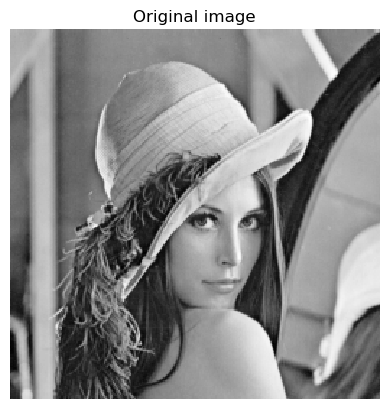

In [3]:
imageplot(f, 'Original image')

### Implement a full wavelet transform

In [4]:
from numpy.linalg import norm
from numpy import power, concatenate, ones, log2, arange, zeros, msort, log10

In [5]:
h = [0, .482962913145, .836516303738, .224143868042, -.129409522551] 
h = h/norm(h)
u = power(-ones(len(h)-1),range(1,len(h))) # alternate +1/-1
g = concatenate(([0], h[-1:0:-1] * u))
Jmin = 0
Jmax = log2(n)-1
fW = f.copy()
for j in arange(Jmax,Jmin-1,-1):
    A = fW[:int(2**(j+1)):,:int(2**(j+1)):]
    for d in arange(1,3):
        Coarse = subsampling(cconv(A,h,d),d)
        Detail = subsampling(cconv(A,g,d),d)
        A = concatenate( (Coarse, Detail), axis=d-1 )
    fW[:int(2**(j+1)):,:int(2**(j+1)):] = A
    j1 = Jmax-j

Check for orthogonality of the transform (conservation of energy).

In [6]:
print( 'Energy of the signal/coefficients = ' + str(norm(f)/norm(fW)) )
#figure(figsize = (10,8))
#plot_wavelet(fW,Jmin);

Energy of the signal/coefficients = 1.0000068


## Inverse 2-D Wavelet transform

Inversing the wavelet transform means retrieving a signal $f1 = \big(f1(x,y):0\leq x,y\leq n-1\big)$ from the
coefficients $fw = \big(fw(k,m): 0\leq k,m\leq n-1\big)$. If $fw$ are exactely the coefficients of $f$, then
$f=f1$ up to machine precision. 

In [7]:
f1 = fW.copy()
for j in arange(Jmin,Jmax+1): 
    A = f1[:int(2**(j+1)):,:int(2**(j+1)):]
    for d in arange(1,3):
        if d==1:
            Coarse = A[:int(2**j):,:]
            Detail = A[int(2**j):int(2**(j+1)):,:]
        else:
            Coarse = A[:,:int(2**j):]
            Detail = A[:,int(2**j):int(2**(j+1)):]
        Coarse = cconv(upsampling(Coarse,d),reverse(h),d)
        Detail = cconv(upsampling(Detail,d),reverse(g),d)
        A = Coarse + Detail
        j1 = Jmax-j
    f1[:int(2**(j+1)):,:int(2**(j+1)):] = A

Check that we recover exactly the original image.

In [8]:
print( 'Error |f-f1|/|f| = ' + str(norm(f-f1)/norm(f)) )

Error |f-f1|/|f| = 1.2722563e-07


## Linear 2-D Wavelet Approximation

Linear approximation is performed by **setting to zero the 'fine scale' or 'high resolution' wavelets coefficients**
and then performing the inverse wavelet transform.

Here we keep only $1/16$ of the wavelet coefficients -- that is $256^2/16 = 4.096$ coefficients compare with the total number of $65.536$ pixels.

In [11]:
fW = perform_wavortho_transf(f,Jmin,+1,h)
eta = 4
fWLin = zeros((n,n))
fWLin[:int(n/eta):,:int(n/eta):] = fW[:int(n/eta):,:int(n/eta):]
fLin = perform_wavortho_transf(fWLin,Jmin,-1,h)

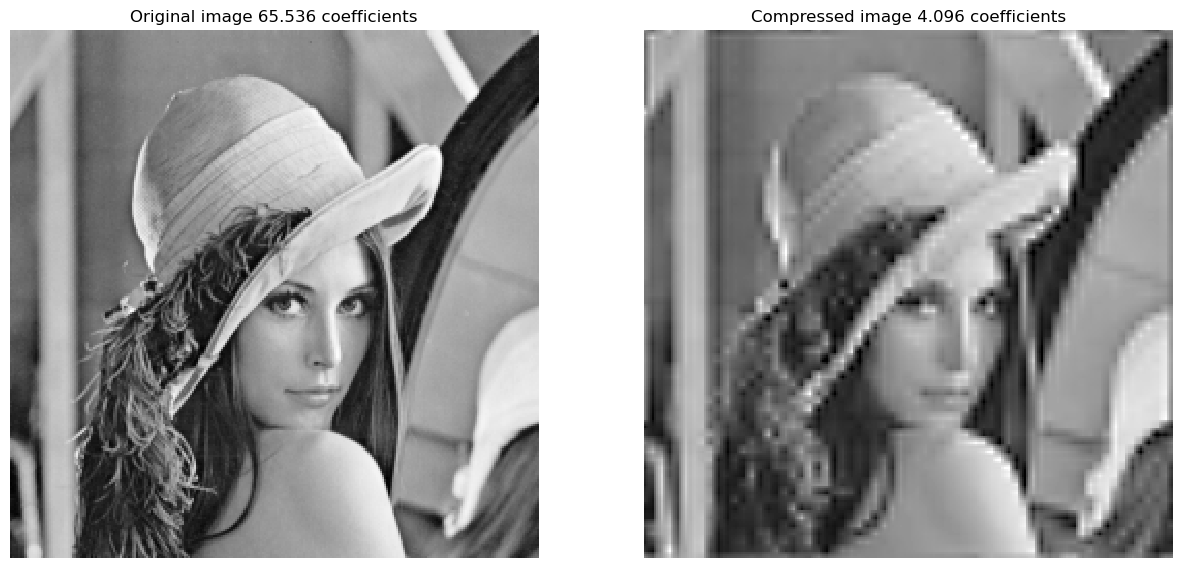

In [12]:
plt.figure(figsize = (15,12))
plt.subplot(121)
imageplot(f, 'Original image 65.536 coefficients')
plt.subplot(122)
imageplot(clamp(fLin), 'Compressed image 4.096 coefficients')
plt.show()

## Threshold 2-D Wavelet Approximation

A non-linear $m$-term approximation is obtained by **keeping only the $m$
largest coefficients**, which creates the smallest possible error.


Removing the smallest coefficients and so keeping only the $m$-largest ones, is
equivalently obtained by thresholding small coefficient to $0$. 


First select a threshold value (the largest the threshold, the more
agressive the approximation).

In [13]:
T = .2

Then set to 0 coefficients with magnitude below the threshold.

In [14]:
fWT = fW * (abs(fW)>T)

Plot the (log of) the coefficient in decaying order.

Text(0.5, 1.0, 'log of the first 5000 wavelets coefficients in decaying order')

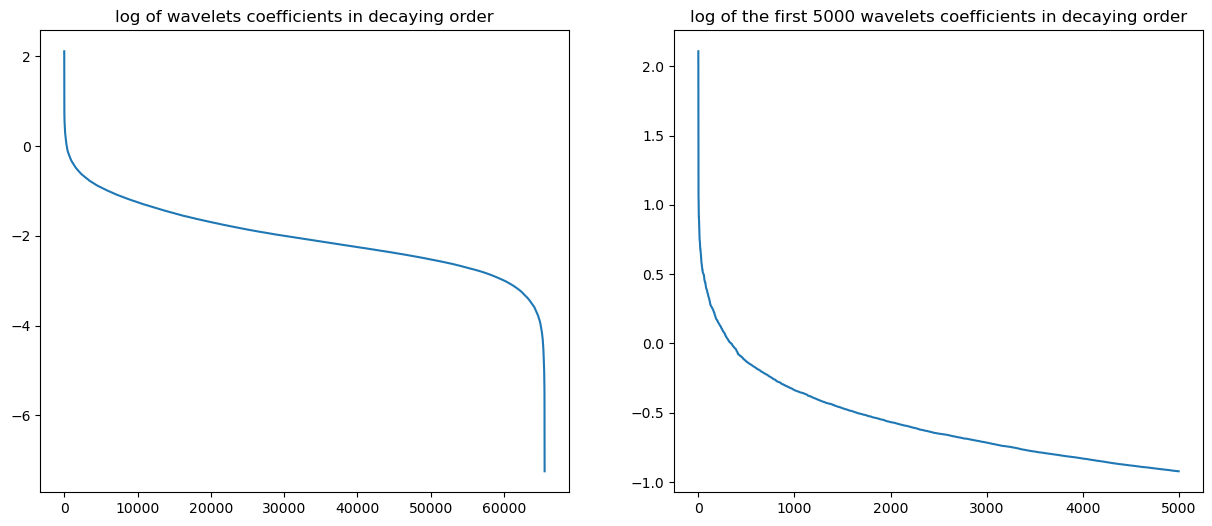

In [18]:
# 256**2 = 65536
v = reverse(np.sort(abs(fW).ravel(), axis=0))
plt.figure(figsize = (15,6))
plt.subplot(121)
plt.plot(log10(v))
plt.axis('tight');
plt.title('log of wavelets coefficients in decaying order')
plt.subplot(122)
thres = 5000
vt = v[0:thres]
plt.plot(log10(vt))
plt.axis('tight');
plt.title('log of the first {} wavelets coefficients in decaying order'.format(thres))
#plt.savefig("log_wavelet_coef.png", bbox_inches='tight')

Find the thresholds $T$ so that the number $m$ of remaining coefficients in the threshold coefficients
are $m=n^2/16$. 

In [19]:
eta = 4 #we keep (100/eta^2) percent of the coefficients
m = round((n**2)/(eta**2))
T = v[m]

Display the corresponding non-linear approximation.

In [20]:
fWT = fW * (abs(fW)>=T)
fnl = perform_wavortho_transf(fWT,Jmin,-1,h)

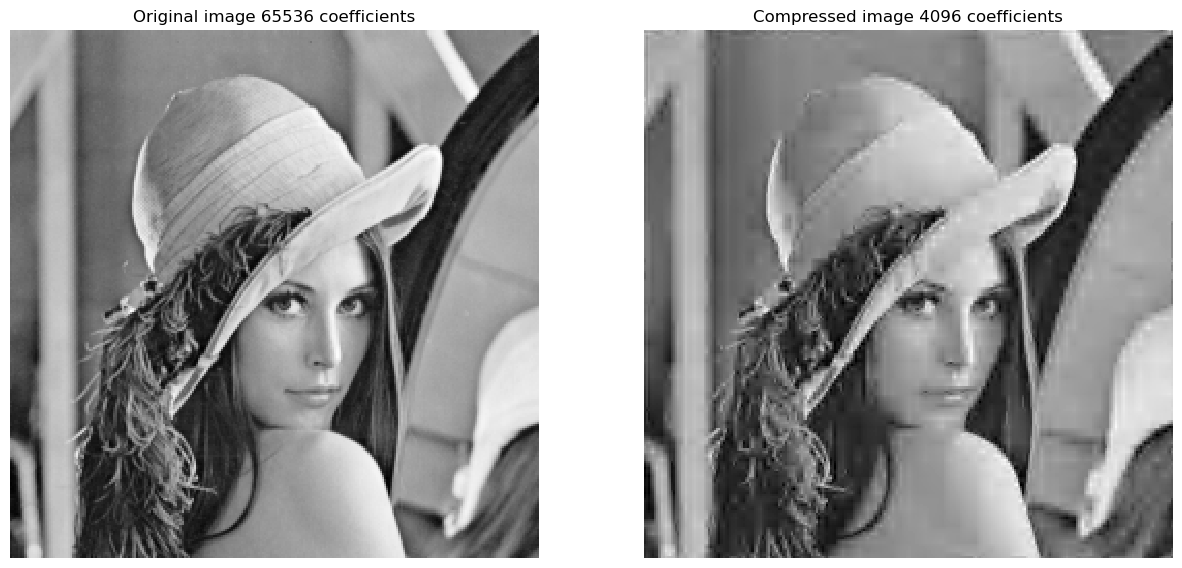

In [21]:
plt.figure(figsize = (15,12))
plt.subplot(121)
imageplot(f, 'Original image {} coefficients'.format(n**2))
plt.subplot(122)
imageplot(clamp(fnl), 'Compressed image {} coefficients'.format(m))
plt.savefig('comparaison_images_lena.png', bbox_inches='tight')

**Exercise:** Compress your own black and white image